<a href="https://colab.research.google.com/github/aghosh92/IEEE_ferroschool_AI_lab_2026/blob/main/notebooks/IEEE_ferroschool_2026_Notebook02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: Simulate & predict polarization maps with neural network

#### Prepared by: Ayana Ghosh
####Contact: ghosha@iitm.ac.in

### Welcome!

This notebook (a) trains small neural network to read the polarization map directly from a noisy image,
(b) uses the measured wall width and amplitude versus temperature to test a Landau theory and *extrapolate* towards the transition temperature.


Import libraries

In [ ]:
import time, warnings, numpy as np, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import least_squares
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from skimage.feature import peak_local_max

In [ ]:
# Set up a clean, reproducible plotting environment and consistent colors
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 100,
                     'image.cmap': 'gray',
                     'axes.spines.top': False,
                     'axes.spines.right': False})
torch.manual_seed(0); np.random.seed(0)

Imaging parameters

In [ ]:
A      = 3.9            # lattice parameter (Å)
PX     = 0.4            # Å per pixel
A_PX   = A / PX         # pixels per unit cell (9.75)
NPIX   = 160            # image is NPIX x NPIX pixels (~16 unit cells)
SIG    = 0.55 / PX      # width of every atomic column (pixels)
AMP_TI = (22 / 82) ** 1.7   # Ti brightness relative to Pb (HAADF intensity ~ Z^1.7)  ->  0.107

In [ ]:
# @title Atom simulator
def wall_profile(x, walls, w):
    """Unit polarization p(x): flips sign across each wall.  x in pixels, wall width w in unit cells."""
    p = np.ones_like(x, dtype=float)
    for xk in walls:
        p = p * np.tanh((x - xk) / (w * A_PX))
    return p

def render(points, amps, sigma=SIG):
    """Draw a Gaussian blob at every (x, y) point."""
    R = int(4 * sigma)
    dy, dx = np.meshgrid(np.arange(-R, R + 1), np.arange(-R, R + 1), indexing="ij")
    cx = np.round(points[:, 0]).astype(int); cy = np.round(points[:, 1]).astype(int)
    X = cx[:, None, None] + dx;  Y = cy[:, None, None] + dy
    g = amps[:, None, None] * np.exp(-((X - points[:, 0, None, None]) ** 2 + (Y - points[:, 1, None, None]) ** 2) / (2 * sigma ** 2))
    ok = (X >= 0) & (X < NPIX) & (Y >= 0) & (Y < NPIX)
    return np.bincount((Y * NPIX + X)[ok], weights=g[ok], minlength=NPIX * NPIX).reshape(NPIX, NPIX)

def simulate(walls, w=0.8, delta0=0.18, dose=300, sign=1, rng=None):
    """Simulate one HAADF-STEM image of a PbTiO3-like crystal with vertical domain walls.
       walls  : x positions (pixels) of the walls          w      : wall width (unit cells)
       delta0 : Ti off-centering deep inside a domain (Å)  dose   : counts at the peak of a Pb column
       sign   : +1 / -1 = polarization direction on the right-hand side of a single wall"""
    rng = rng if rng is not None else np.random.default_rng()
    n = int(NPIX / A_PX) + 3
    sx, sy = rng.uniform(0, A_PX, 2)                                   # random sub-cell shift of the lattice
    gx, gy = np.meshgrid(np.arange(-1, n) * A_PX + sx, np.arange(-1, n) * A_PX + sy)
    pb = np.stack([gx.ravel(), gy.ravel()], 1)                         # Pb on a square grid
    centres = pb + A_PX / 2                                            # centre of each Pb cage
    P_of_x = lambda x: sign * delta0 * wall_profile(x, walls, w)       # polarization (Å) pointing along +y (down)
    Py = P_of_x(centres[:, 0])
    ti = centres.copy();  ti[:, 1] -= Py / PX                          # Ti sits at the centre MINUS the polarization
    pb = pb + rng.normal(0, 0.03 / PX, pb.shape)                       # small random atom displacements (0.03 Å)
    ti = ti + rng.normal(0, 0.03 / PX, ti.shape)
    clean = render(pb, np.ones(len(pb))) + render(ti, AMP_TI * np.ones(len(ti)))
    img = rng.poisson(dose * (clean + 0.03)).astype(float)             # shot noise (+ weak constant background)
    truth_map = np.tile(P_of_x(np.arange(NPIX)), (NPIX, 1))            # ground-truth P_y at every pixel
    inside = lambda p: (p[:, 0] > 0) & (p[:, 0] < NPIX) & (p[:, 1] > 0) & (p[:, 1] < NPIX)
    m = inside(centres)
    return dict(img=img, truth_map=truth_map, P_of_x=P_of_x, pb=pb[inside(pb)], ti=ti[m], centres=centres[m],
                Py=Py[m], walls=walls, w=w, delta0=delta0, dose=dose)

In [ ]:
# @title Classical atom finder
# ===== classical atom finder and tanh fit =====
def fit_column(img, x0, y0, sigma=None, R=5):
    """Fit a 2D Gaussian (amplitude, centre, background; plus width if sigma is None) in a small window."""
    xi, yi = int(round(x0)), int(round(y0))
    if xi - R < 0 or yi - R < 0 or xi + R >= img.shape[1] or yi + R >= img.shape[0]:
        return None
    win = img[yi - R:yi + R + 1, xi - R:xi + R + 1]
    X, Y = np.meshgrid(np.arange(xi - R, xi + R + 1), np.arange(yi - R, yi + R + 1))
    disk = (X - xi) ** 2 + (Y - yi) ** 2 <= R ** 2          # circular window: keeps the neighbouring Ti out of a Pb fit
    X, Y, win = X[disk], Y[disk], win[disk]
    if sigma is None:
        f  = lambda c, A_, x, y, b, s: A_ * np.exp(-((c[0] - x) ** 2 + (c[1] - y) ** 2) / (2 * s ** 2)) + b
        p0 = [win.max() - win.min(), x0, y0, win.min(), 1.4]
    else:
        f  = lambda c, A_, x, y, b: A_ * np.exp(-((c[0] - x) ** 2 + (c[1] - y) ** 2) / (2 * sigma ** 2)) + b
        p0 = [max(win.max() - win.min(), 1e-3), x0, y0, win.min()]
    try:
        p, _ = curve_fit(f, (X, Y), win, p0=p0, maxfev=300)
    except RuntimeError:
        return None
    return p                                                            # A, x, y, background, [sigma]

def find_atoms(img):
    """1) find + refine the bright Pb columns   2) subtract them   3) find the faint Ti column in every Pb square
       4) polarization of each cell  P = -(Ti position - centre of its 4 Pb)  (in Å)"""
    sm = ndi.gaussian_filter(img, 1.5)
    base, hi = np.median(sm), np.percentile(sm, 99.7)
    peaks = peak_local_max(sm, min_distance=4, threshold_abs=base + 0.4 * (hi - base))[:, ::-1].astype(float)
    fits = [(p, fit_column(img, *p, R=4)) for p in peaks]      # small window: stays clear of the neighbouring Ti columns
    fits = [f for _, f in fits if f is not None and 0.5 < f[4] < 3]
    pb  = np.array([f[1:3] for f in fits]);  amp = np.array([f[0] for f in fits]);  sig = np.median([f[4] for f in fits])
    resid = img - render(pb, amp, sig)                                  # image with the Pb columns removed
    tree = cKDTree(pb);  a = np.median(tree.query(pb, k=2)[0][:, 1])    # nearest-neighbour Pb distance
    centres = []
    for p in pb:                                                        # complete Pb squares -> cage centres
        quad = []
        for d in ([a, 0], [0, a], [a, a]):
            dist, j = tree.query(p + d)
            if dist > 0.3 * a: break
            quad.append(pb[j])
        else:
            centres.append(np.mean([p] + quad, axis=0))
    centres = np.array(centres);  ti, keep = [], []
    for i, c in enumerate(centres):
        f = fit_column(resid, c[0], c[1], sigma=sig, R=4)
        if f is not None and np.hypot(f[1] - c[0], f[2] - c[1]) < 0.3 * a and f[0] > 0.25 * AMP_TI * np.median(amp):
            ti.append(f[1:3]);  keep.append(i)
    ti, centres = np.array(ti), centres[keep]
    return dict(pb=pb, ti=ti, centres=centres, P=-(ti - centres) * PX, sigma=sig)

def fit_wall(x, Py):
    """Fit P(x) = P0 * tanh((x - x0) / w) to scattered values.  Returns P0 (Å), x0 (px), w (unit cells)."""
    s0 = np.sign(np.mean(Py[x > np.median(x)]) - np.mean(Py[x < np.median(x)])) or 1
    f = lambda x, P0, x0, w: P0 * np.tanh((x - x0) / w)
    p, _ = curve_fit(f, x, Py, p0=[s0 * 0.15, np.median(x), 8.0], bounds=([-1, 0, 0.5], [1, NPIX, 80]))
    return abs(p[0]), p[1], p[2] / A_PX

## 1. Training data
The network sees only a noisy image and has to output the map of $P_y$ (in Å) at every pixel. We train it on simulated images with 0–3 walls, random wall width (0.5–1.3 cells), random $P_0$ (0.10–0.23 Å) and random dose (30–1000 counts). Remember these ranges, because they matter in section 5.

simulated 440 images in 5 s | training input (400, 1, 160, 160)


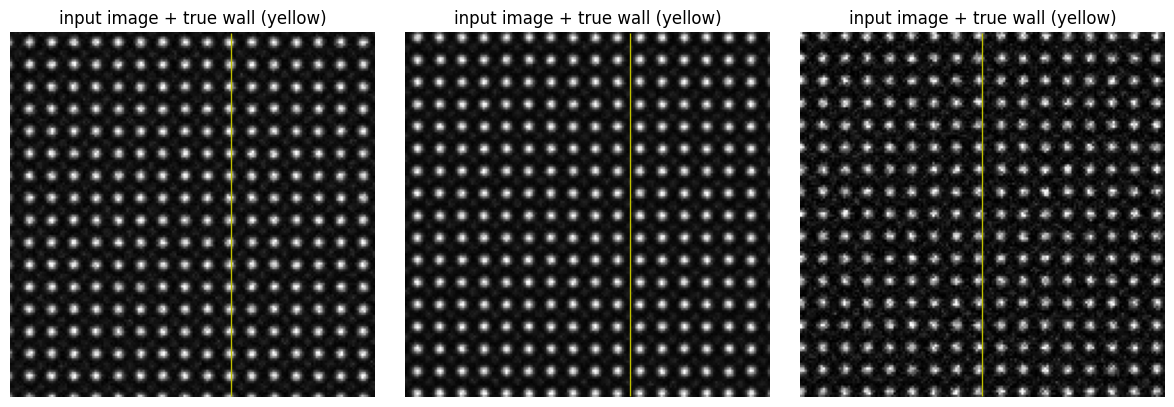

In [ ]:
P_SCALE = 0.15 # Å
def norm(img):
    med = np.median(img)
    return ((img - med) / (np.percentile(img, 99.5) - med + 1e-6)).astype(np.float32)

def random_sample(rng):
    k = rng.choice([0, 1, 2, 3], p=[.1, .5, .2, .2])
    xs = np.sort(rng.choice(np.arange(25, 136, 25), k, replace=False) + rng.uniform(-5, 5, k))
    return simulate(list(xs), w=rng.uniform(.5, 1.3), delta0=rng.uniform(.10, .23),
                    dose=np.exp(rng.uniform(np.log(30), np.log(1000))),
                    sign=int(rng.choice([-1, 1])), rng=rng)

def make_set(n, seed):
    rng = np.random.default_rng(seed); S = [random_sample(rng) for _ in range(n)]
    X = torch.tensor(np.stack([norm(s["img"]) for s in S])[:, None])
    Y = torch.tensor((np.stack([s["truth_map"] for s in S]) / P_SCALE)[:, None],
                     dtype=torch.float32)
    return X, Y

t0 = time.time(); Xtr, Ytr = make_set(400, 1); Xva, Yva = make_set(40, 2)
print(f"simulated 440 images in {time.time()-t0:.0f} s | training input {tuple(Xtr.shape)}")
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, i in zip(ax, (0, 1, 2)):
    a.imshow(Xtr[i, 0], vmax=1); a.contour(Ytr[i, 0], [0], colors="y", linewidths=1)
    a.set_title("input image + true wall (yellow)"); a.axis("off")
plt.tight_layout()
plt.show()

## 2. The network
A tiny **U-Net** (two down-sampling steps, only ~30 000 parameters): convolutions look at a few unit cells at a time, the down-sampling path adds wider context so the network can see where the wall is, and skip connections keep fine detail. Loss = mean squared error on the $P_y$ map. We train on random 96×96 crops and flip the images (a vertical flip also flips the sign of $P_y$).

In [ ]:
class TinyUNet(nn.Module):
    def __init__(s, c=8):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1),
                                         nn.BatchNorm2d(o), nn.ReLU(),
                                         nn.Conv2d(o, o, 3, padding=1),
                                         nn.BatchNorm2d(o), nn.ReLU())
        s.e1, s.e2, s.mid = blk(1, c), blk(c, 2 * c), blk(2 * c, 4 * c)
        s.d2, s.d1, s.out = blk(4 * c + 2 * c, 2 * c), blk(2 * c + c, c), nn.Conv2d(c, 1, 1)
    def forward(s, x):
        e1 = s.e1(x); e2 = s.e2(F.max_pool2d(e1, 2)); m = s.mid(F.max_pool2d(e2, 2))
        up = lambda t: F.interpolate(t, scale_factor=2)
        d2 = s.d2(torch.cat([up(m), e2], 1)); d1 = s.d1(torch.cat([up(d2), e1], 1))
        return s.out(d1)

parameters: 0.03 M


step  200  train loss 0.104 | validation loss 0.293 | 26 s


step  400  train loss 0.096 | validation loss 0.126 | 52 s


step  600  train loss 0.105 | validation loss 0.053 | 79 s


step  800  train loss 0.056 | validation loss 0.055 | 103 s


step 1000  train loss 0.168 | validation loss 0.043 | 128 s


step 1200  train loss 0.077 | validation loss 0.042 | 153 s


Training the model

In [ ]:
model = TinyUNet(); print("parameters: %.2f M" % (sum(p.numel() for p in model.parameters()) / 1e6))
STEPS, CROP, BS = 1200, 96, 8
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=STEPS, pct_start=.15)
t0 = time.time()
for step in range(1, STEPS + 1):
    model.train(); idx = torch.randint(0, len(Xtr), (BS,))
    oy, ox = np.random.randint(0, NPIX - CROP + 1, 2)
    x, y = Xtr[idx, :, oy:oy + CROP, ox:ox + CROP], Ytr[idx, :, oy:oy + CROP, ox:ox + CROP]
    if np.random.rand() < .5: x, y = x.flip(-1), y.flip(-1) # mirror left-right: P_y unchanged
    if np.random.rand() < .5: x, y = x.flip(-2), -y.flip(-2) # mirror up-down: P_y changes sign
    loss = F.mse_loss(model(x), y); opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    if step % 200 == 0:
        model.eval()
        with torch.no_grad(): v = F.mse_loss(model(Xva), Yva).item()
        print(f"step {step:4d}  train loss {loss.item():.3f} | validation loss {v:.3f} | {time.time()-t0:.0f} s")

### What the network predicts
A 2-wall image at low dose (left), the network's polarization map (middle) and the truth (right).

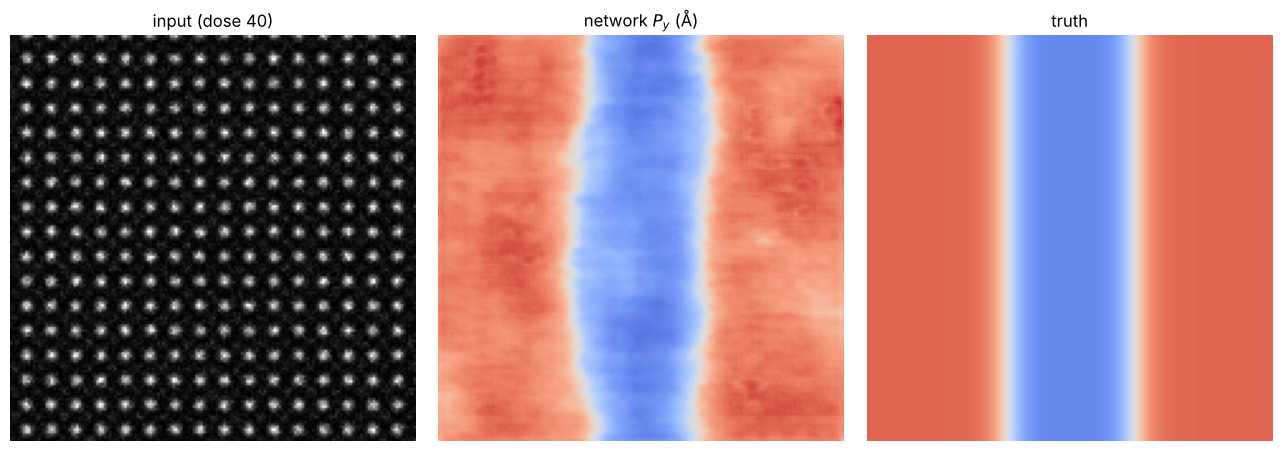

In [ ]:
@torch.no_grad()
def predict(img):
    model.eval(); return model(torch.tensor(norm(img)[None, None])).numpy()[0, 0] * P_SCALE

s = simulate([55, 105], w=0.7, delta0=0.18, dose=40, rng=np.random.default_rng(7)); pred = predict(s["img"])
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4)); kw = dict(cmap="coolwarm", vmin=-.25, vmax=.25)
ax[0].imshow(s["img"], vmax=np.percentile(s["img"], 99.8)); ax[0].set_title("input (dose 40)")
ax[1].imshow(pred, **kw); ax[1].set_title("network $P_y$ (Å)"); ax[2].imshow(s["truth_map"], **kw); ax[2].set_title("truth")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Network vs the classical pipeline
Same test images, same cells: error of $P_y$ (pm) for the classical atom-by-atom measurement and for the network (map value at each cell centre), across dose.

In [ ]:
def smooth_cells(a, sigma_cells=1.0):
    """classical P_y averaged over neighbouring cells (Gaussian weights): what a smooth map does"""
    c = a["centres"]; d2 = ((c[:, None, :] - c[None, :, :]) ** 2).sum(-1)
    wgt = np.exp(-d2 / (2 * (sigma_cells * A_PX) ** 2)); return wgt @ a["P"][:, 1] / wgt.sum(1)

def cell_values(a, pred):
    c = a["centres"]; ix = np.clip(np.round(c[:, 0]).astype(int), 0, NPIX - 1); iy = np.clip(np.round(c[:, 1]).astype(int), 0, NPIX - 1)
    return pred[iy, ix]

doses, out = [30, 100, 300, 1000], []
for d in doses:
    ec, es, en = [], [], []
    for k in range(5):
        r = np.random.default_rng(5000 + k)
        si = simulate([r.uniform(60, 100)], w=r.uniform(.6, 1.2), delta0=r.uniform(.12, .22), dose=d, sign=int(r.choice([-1, 1])), rng=r)
        a = find_atoms(si["img"]); truth = si["P_of_x"](a["centres"][:, 0])
        ec.append(a["P"][:, 1] - truth); es.append(smooth_cells(a) - truth); en.append(cell_values(a, predict(si["img"])) - truth)
    out.append([100 * np.sqrt(np.mean(np.concatenate(e) ** 2)) for e in (ec, es, en)])
print(f"{'dose':>5} | {'classical (pm)':>14} {'classical, averaged (pm)':>24} {'network (pm)':>13}")
for d, (c_, s_, n_) in zip(doses, out): print(f"{d:5d} | {c_:14.1f} {s_:24.1f} {n_:13.1f}")

 dose | classical (pm) classical, averaged (pm)  network (pm)
   30 |           18.3                      5.8           4.3
  100 |            9.0                      3.3           2.4
  300 |            6.1                      2.5           2.0
 1000 |            4.2                      2.0           1.6


## 4. The physics: Landau theory of the wall
Write the energy of a ferroelectric as a polynomial in $P$ plus a cost for gradients (this is Landau–Ginzburg–Devonshire theory):

$$f=\frac{\alpha}{2}P^2+\frac{\beta}{4}P^4+\frac{g}{2}\Big(\frac{dP}{dx}\Big)^2,\qquad \alpha=\alpha_0\,(T-T_c).$$

Below $T_c$, $\alpha<0$ and the energy has two minima, $\pm P_0$. The $\tanh$ wall is the exact solution that connects them, and its two parameters follow from $\alpha,\beta,g$:

$$P_0=\sqrt{\frac{|\alpha|}{\beta}}\;\propto\;(T_c-T)^{1/2},\qquad w=\sqrt{\frac{2g}{|\alpha|}}\;\propto\;(T_c-T)^{-1/2}\quad\Longrightarrow\quad P_0\,w=\sqrt{2g/\beta}=\text{constant}.$$

So as we approach $T_c$ the polarization **shrinks** and the wall **broadens and diverges**, and both are controlled by the same $T_c$. We can test this and use it to extrapolate.

**The experiment.** Pretend $T_c=600$ K and that the true crystal obeys the law above ($P_0=0.20\sqrt{1-T/T_c}$ Å, $w=0.55/\sqrt{1-T/T_c}$ cells). Simulate ten images at each temperature, measure $P_0$ and $w$, **fit $T_c$ using only $T\le400$ K**, and then check the predictions for $T=450$–$570$ K, which we pretend we never measured. We measure in two ways: the classical per-atom tanh fit, and the tanh fit to the network's map.

*(This is a toy: real PbTiO$_3$ has a first-order transition near 760 K, where $P$ jumps to zero rather than shrinking smoothly.)*

In [ ]:
TC, D00, W00, DOSE = 600.0, 0.20, 0.55, 300
truth = lambda T: (D00 * np.sqrt(1 - T / TC), W00 / np.sqrt(1 - T / TC))        # P0 (Å), w (cells)
T_FIT, T_HOLD, N_REP = [100, 200, 300, 400], [450, 500, 540, 570], 10
rows_y = np.arange(12, NPIX - 12)

def fit_wall_map(pred):
    """tanh fit to the row-averaged network map"""
    prof = pred[rows_y].mean(0); x = np.arange(NPIX); return fit_wall(x, prof)

meas = {}; t0 = time.time()
for T in T_FIT + T_HOLD:
    P0t, wt = truth(T); c, n = [], []
    for k in range(N_REP):
        r = np.random.default_rng(9000 + int(T) + k)
        si = simulate([r.uniform(60, 100)], w=wt, delta0=P0t, dose=DOSE, sign=int(r.choice([-1, 1])), rng=r)
        a = find_atoms(si["img"]); c.append(fit_wall(a["centres"][:, 0], a["P"][:, 1])[::2])   # (P0, w)
        n.append(fit_wall_map(predict(si["img"]))[::2])
    meas[T] = dict(cls=np.array(c), nn=np.array(n))
print(f"measured {len(meas)} temperatures x {N_REP} images in {time.time()-t0:.0f} s")

measured 8 temperatures x 10 images in 40 s


### Fit the Landau law on $T\le400$ K, extrapolate

classical: fitted T_c =    587 K   (true 600)   P0*w = 0.113 Å·cell   (true 0.110)
network  : fitted T_c =    803 K   (true 600)   P0*w = 0.146 Å·cell   (true 0.110)


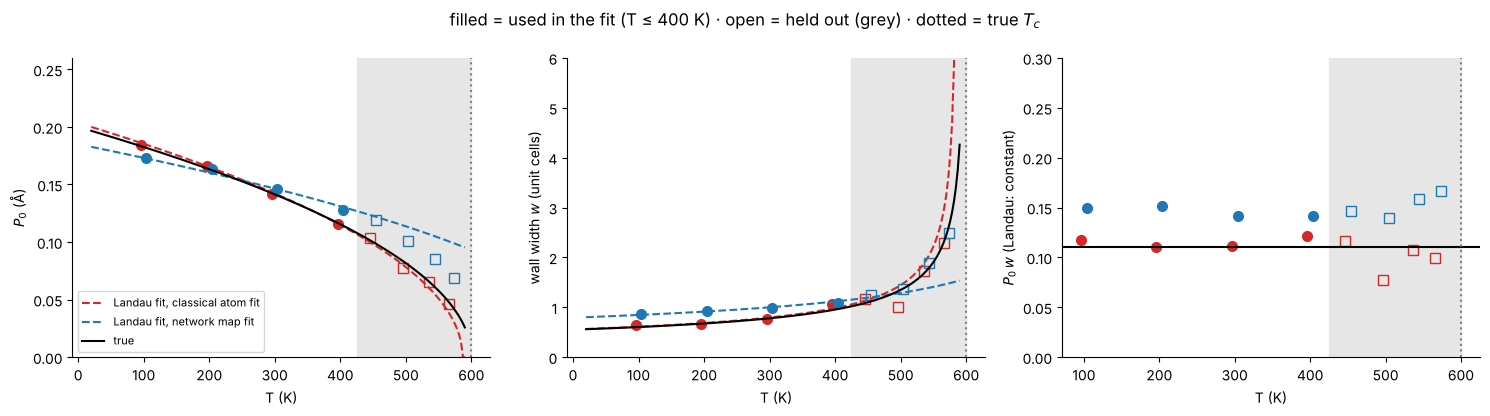


   T | true P0 cls pred cls meas  NN meas || true w cls pred cls meas  NN meas
 450 |   0.100    0.098    0.103    0.119 ||   1.10     1.15     1.16     1.24
 500 |   0.082    0.078    0.078    0.101 ||   1.35     1.44     1.00     1.36
 540 |   0.063    0.057    0.065    0.085 ||   1.74     1.97     1.73     1.89
 570 |   0.045    0.034    0.046    0.069 ||   2.46     3.29     2.30     2.49


In [ ]:
def lgd_fit(method):
    T = np.array(T_FIT, float)
    P  = np.array([np.median(meas[t][method][:, 0]) for t in T_FIT]); sP = np.array([max(meas[t][method][:, 0].std() / np.sqrt(N_REP), 0.003) for t in T_FIT])
    iw = np.array([np.median(1 / meas[t][method][:, 1]) for t in T_FIT]); siw = np.array([max((1 / meas[t][method][:, 1]).std() / np.sqrt(N_REP), 0.03) for t in T_FIT])
    def res(th):
        Tc, A_, B_ = th; s = np.sqrt(np.maximum(Tc - T, 1e-6)); return np.r_[(P - A_ * s) / sP, (iw - B_ * s) / siw]
    return least_squares(res, [650., .01, .05]).x                        # Tc, A (P0 = A sqrt(Tc-T)), B (1/w = B sqrt(Tc-T))

fits = {m: lgd_fit(m) for m in ("cls", "nn")}
for m, lab in (("cls", "classical"), ("nn", "network  ")):
    Tc_, A_, B_ = fits[m]; print(f"{lab}: fitted T_c = {Tc_:6.0f} K   (true {TC:.0f})   P0*w = {A_/B_:.3f} Å·cell   (true {D00*W00:.3f})")

Tg = np.linspace(20, 590, 200); col = {"cls": "C3", "nn": "C0"}; lab = {"cls": "classical atom fit", "nn": "network map fit"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for m in ("cls", "nn"):
    Tc_, A_, B_ = fits[m]; s_ = np.sqrt(np.maximum(Tc_ - Tg, 1e-6)); off = -4 if m == "cls" else 4
    ax[0].plot(Tg, A_ * s_, "--", color=col[m], label=f"Landau fit, {lab[m]}"); ax[1].plot(Tg, np.minimum(1 / (B_ * s_), 8), "--", color=col[m])
    for T in T_FIT + T_HOLD:
        f = "o" if T in T_FIT else "s"; fc = col[m] if T in T_FIT else "none"; x = meas[T][m]
        ax[0].plot(T + off, np.median(x[:, 0]), f, color=col[m], mfc=fc, ms=7); ax[1].plot(T + off, np.median(x[:, 1]), f, color=col[m], mfc=fc, ms=7)
        ax[2].plot(T + off, np.median(x[:, 0] * x[:, 1]), f, color=col[m], mfc=fc, ms=7)
ax[0].plot(Tg, truth(Tg)[0], "k", label="true"); ax[1].plot(Tg, truth(Tg)[1], "k"); ax[2].axhline(D00 * W00, color="k")
for a, yl in zip(ax, ("$P_0$ (Å)", "wall width $w$ (unit cells)", "$P_0\\,w$ (Landau: constant)")):
    a.axvspan(min(T_HOLD) - 25, TC, color="0.9", zorder=0); a.axvline(TC, color="0.5", ls=":"); a.set_xlabel("T (K)"); a.set_ylabel(yl)
ax[0].set_ylim(0, .26); ax[1].set_ylim(0, 6); ax[2].set_ylim(0, .3); ax[0].legend(fontsize=8, loc="lower left")
plt.suptitle("filled = used in the fit (T ≤ 400 K) · open = held out (grey) · dotted = true $T_c$"); plt.tight_layout(); plt.show()

print(f"\n{'T':>4} | {'true P0':>7} {'cls pred':>8} {'cls meas':>8} {'NN meas':>8} || {'true w':>6} {'cls pred':>8} {'cls meas':>8} {'NN meas':>8}")
for T in T_HOLD:
    P0t, wt = truth(T); Tc_, A_, B_ = fits["cls"]; s_ = np.sqrt(max(Tc_ - T, 1e-6))
    print(f"{T:4d} | {P0t:7.3f} {A_*s_:8.3f} {np.median(meas[T]['cls'][:,0]):8.3f} {np.median(meas[T]['nn'][:,0]):8.3f} || {wt:6.2f} {min(1/(B_*s_),99):8.2f} {np.median(meas[T]['cls'][:,1]):8.2f} {np.median(meas[T]['nn'][:,1]):8.2f}")

## 5. Where does the network's $T_c$ error come from?
The network was trained on $P_0\ge0.10$ Å and $w\le1.3$ cells. The held-out temperatures go outside that range, but the $T_c$ fit only uses $T\le400$ K, which are all inside it. Compare the network's measurements at the fitted temperatures:

In [ ]:
print("training range : P0 in [0.10, 0.23] Å, w in [0.5, 1.3] cells")
print("held-out truth : P0 =", [round(float(truth(T)[0]), 3) for T in T_HOLD], "Å ,  w =", [round(float(truth(T)[1]), 2) for T in T_HOLD], "cells")
print(f"\n{'T':>4} | {'true w':>6} {'network w':>9} {'classical w':>11} | {'true P0':>7} {'network P0':>10}")
for T in T_FIT + T_HOLD:
    P0t, wt = truth(T)
    print(f"{T:4d} | {wt:6.2f} {np.median(meas[T]['nn'][:, 1]):9.2f} {np.median(meas[T]['cls'][:, 1]):11.2f} | {P0t:7.3f} {np.median(meas[T]['nn'][:, 0]):10.3f}"
          + ("   <- used in the T_c fit" if T in T_FIT else ""))

training range : P0 in [0.10, 0.23] Å, w in [0.5, 1.3] cells
held-out truth : P0 = [0.1, 0.082, 0.063, 0.045] Å ,  w = [1.1, 1.35, 1.74, 2.46] cells

   T | true w network w classical w | true P0 network P0
 100 |   0.60      0.86        0.65 |   0.183      0.173   <- used in the T_c fit
 200 |   0.67      0.93        0.67 |   0.163      0.163   <- used in the T_c fit
 300 |   0.78      0.98        0.77 |   0.141      0.146   <- used in the T_c fit
 400 |   0.95      1.08        1.07 |   0.115      0.128   <- used in the T_c fit
 450 |   1.10      1.24        1.16 |   0.100      0.119
 500 |   1.35      1.36        1.00 |   0.082      0.101
 540 |   1.74      1.89        1.73 |   0.063      0.085
 570 |   2.46      2.49        2.30 |   0.045      0.069


### Reading the result (numbers from the saved run; retraining changes the network's slightly)
* **Classical + Landau:** fitted $T_c\approx 590$ K (true 600 K) and $P_0 w\approx 0.11$ (true 0.110). Predicted held-out $P_0$ (0.098, 0.078, 0.057, 0.034 Å) is close to the measured and true values (true 0.100, 0.082, 0.063, 0.045). The *width* prediction is poorer near $T_c$ (3.3 cells predicted at 570 K, true 2.46) because $w$ diverges there and a small error in $T_c$ gets amplified.
* **Network:** its per-cell error at low dose is several times smaller than the classical one (section 3), but it measures the walls too wide even inside its training range, most at low $T$ where the walls are narrowest (0.86 cells at 100 K, true 0.60; section 5). The $T_c$ fit uses only these $T\le400$ K points, so its fitted $T_c$ comes out near 800 K ($P_0 w\approx0.15$ instead of 0.11). Above 400 K, outside its training range, its $P_0$ also stays too high (0.069 Å at 570 K, true 0.045), but those points are not used in the fit.

## What you learned
* A small U-Net can read the polarization map directly from noisy pixels; compare its error with the classical pipeline in section 3.
* Landau theory ties the wall width and the polarization amplitude together through a single $T_c$, so measuring them at low temperature lets you **predict** their behaviour near $T_c$. That is physics doing the extrapolating.
* A neural network only knows what it was trained on. Anything outside its training range (here: smaller $P_0$, wider walls) is a prediction the network was never shown, so check it against an independent measurement before building physics on it.

**Ideas for extending this:** a first-order (sixth-order) Landau model, 90° walls with polarization rotating by 90°, realistic multislice simulations for the images, or a network that outputs $P_0$, $w$ and $x_0$ directly.